# Nano-Tox Database 
Author: Chi-Yun Chen

Date: Jan 15, 2025; Nov 17, 2026

Description: Data preprocessing for both internal and external datasets

**You already created the virtual environment (preproc_env) and registered it as a Jupyter kernel.**
How to do it?
Go to File -> New -> Terminal
Enter:
python3.10 -m venv ~/preproc_env 
source ~/preproc_env/bin/activate 
pip install numpy pandas pyarrow mendeleev
pip install ipykernel
python -m ipykernel install --user --name=preproc_env --display-name "Python (preproc_env)"

**Switch your notebook to the new kernel**
In your notebook: Kernel → Change Kernel → Python (preproc_env)

***Do not run !pip install here — package installation is handled in the terminal.

In [1]:
# Install basic python pcakges
import numpy as np
import pandas as pd

import pyarrow as pa
import re
from mendeleev import element

import matplotlib.pyplot as plt
import seaborn as sns

print("All packages loaded successfully!")

All packages loaded successfully!


# Internal dataset

In [2]:
Final = pd.read_csv('Raw.csv')  # Sample size at this stage: 9639
Final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9639 entries, 0 to 9638
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Source             9639 non-null   object 
 1   Year               9639 non-null   int64  
 2   DOI_No.            9639 non-null   int64  
 3   DOI                9639 non-null   object 
 4   Cell_viability     7252 non-null   float64
 5   Cytotoxicity       9639 non-null   object 
 6   Core               9639 non-null   object 
 7   Diameter           9639 non-null   float64
 8   Hydrodynamic_size  9639 non-null   object 
 9   Zeta_potential     9639 non-null   object 
 10  Surf_func          9639 non-null   object 
 11  Assay_viability    9639 non-null   object 
 12  Test_indicator     9639 non-null   object 
 13  Time               9639 non-null   float64
 14  Concentration      9639 non-null   float64
 15  Cell_morphol       9639 non-null   object 
 16  Cell_type          9639 

In [3]:
# Rearrange DOI
cats = pd.Categorical(
    Final['DOI'],
    categories=Final['DOI'].unique(),  # in order of appearance
    ordered=True
)
Final['DOI_No.'] = cats.codes + 1

# Add 2 new NP properties: electronegativity and molecular weight of core material

In [4]:
def get_material_properties_optimized(formula):
    """
    Parses a chemical formula and returns molecular weight and average
    Pauling electronegativity as a tuple.
    """
    if not isinstance(formula, str):
        return (np.nan, np.nan)
    try:
        parts = re.findall(r'([A-Z][a-z]*)(\d*)', formula)
        if not parts or ''.join([''.join(p) for p in parts]) != formula:
             raise ValueError("Invalid or complex formula")

        total_weight = 0
        total_en_sum = 0
        atom_count = 0
        for symbol, count_str in parts:
            el = element(symbol)
            count = int(count_str) if count_str else 1
            total_weight += el.atomic_weight * count
            
            # Mendeleev can return None for electronegativity
            en = el.electronegativity('pauling')
            if en is None:
                return (np.nan, np.nan) # Handle elements without this property
                
            total_en_sum += en * count
            atom_count += count
        
        avg_electronegativity = total_en_sum / atom_count
        return (total_weight, avg_electronegativity)
    
    except (ValueError, AttributeError):
        return (np.nan, np.nan)

In [5]:
# Extract unique core formulas
unique_cores = Final['Core'].dropna().unique()

# Compute properties once per unique formula
props = {core: get_material_properties_optimized(core) for core in unique_cores}

In [6]:
# Build mapping dicts for weight and electronegativity
mw_map = {core: val[0] for core, val in props.items()}
en_map = {core: val[1] for core, val in props.items()}

# Map the results back into the original DataFrame
Final['Mol_weight'] = Final['Core'].map(mw_map)
Final['Electronegativity'] = Final['Core'].map(en_map)

In [7]:
import re

def expand_parentheses(formula):
    """Expand parentheses so the formula parser can handle them.
    Ca10(PO4)6(OH)2 -> Ca10P6O24O2H2 ; Fe4(Fe(CN)6)3 -> Fe4Fe3C18N18
    """
    pat = re.compile(r'\(([^()]+)\)(\d*)')
    while '(' in formula:
        def repl(m):
            mult = int(m.group(2)) if m.group(2) else 1
            return ''.join(sym + str(int(num or 1) * mult)
                           for sym, num in re.findall(r'([A-Z][a-z]*)(\d*)', m.group(1)))
        formula = pat.sub(repl, formula)
    return formula

# --- Parenthesized formulas: same function as every other row ---
for core in ['Ca10(PO4)6(OH)2', 'Fe4(Fe(CN)6)3']:
    mw, chi = get_material_properties_optimized(expand_parentheses(core))
    m = Final['Core'] == core
    Final.loc[m & Final['Mol_weight'].isna(), 'Mol_weight'] = mw
    Final.loc[m & Final['Electronegativity'].isna(), 'Electronegativity'] = chi
    print(f"{core}: MW = {mw:.2f}, EN = {chi:.3f}")
# expect: Ca10(PO4)6(OH)2: MW = 1004.61, EN = 2.659  (HAP)
#         Fe4(Fe(CN)6)3:   MW = 859.24,  EN = 2.638  (Prussian blue)

# --- Ag/Au alloy: mean of constituents from mendeleev's own values ---
# (assumes ~50:50; reweight if the paper reports a different ratio)
ag, au = element('Ag'), element('Au')
alloy_mw = (ag.atomic_weight + au.atomic_weight) / 2
alloy_en = (ag.electronegativity('pauling') + au.electronegativity('pauling')) / 2
print(f"Ag/Au: MW = {alloy_mw:.2f}, EN = {alloy_en:.3f}")  # expect 152.42, 2.165
m = Final['Core'] == 'Ag/Au'
Final.loc[m & Final['Mol_weight'].isna(), 'Mol_weight'] = alloy_mw
Final.loc[m & Final['Electronegativity'].isna(), 'Electronegativity'] = alloy_en

# --- Guardrail: surface any core still missing descriptors ---
for col in ['Mol_weight', 'Electronegativity']:
    missing = Final.loc[Final[col].isna(), 'Core'].unique()
    if len(missing):
        print(f"WARNING: {col} still NaN for cores: {list(missing)}")

Ca10(PO4)6(OH)2: MW = 1004.61, EN = 2.659
Fe4(Fe(CN)6)3: MW = 859.24, EN = 2.638
Ag/Au: MW = 152.42, EN = 2.165


In [8]:
Final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9639 entries, 0 to 9638
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Source             9639 non-null   object 
 1   Year               9639 non-null   int64  
 2   DOI_No.            9639 non-null   int16  
 3   DOI                9639 non-null   object 
 4   Cell_viability     7252 non-null   float64
 5   Cytotoxicity       9639 non-null   object 
 6   Core               9639 non-null   object 
 7   Diameter           9639 non-null   float64
 8   Hydrodynamic_size  9639 non-null   object 
 9   Zeta_potential     9639 non-null   object 
 10  Surf_func          9639 non-null   object 
 11  Assay_viability    9639 non-null   object 
 12  Test_indicator     9639 non-null   object 
 13  Time               9639 non-null   float64
 14  Concentration      9639 non-null   float64
 15  Cell_morphol       9639 non-null   object 
 16  Cell_type          9639 

In [9]:
import sys
!{sys.executable} -m pip install matplotlib


[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


In [10]:
import matplotlib.pyplot as plt

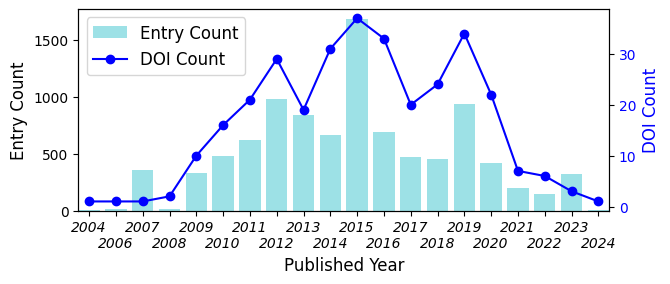

In [11]:
with_year = Final.dropna(subset=['Year'])

# Count DOIs per year (unique count)
doi_counts = with_year.groupby(with_year['Year'].astype(int))['DOI'].nunique()

# Count entries per year (total rows per year)
entry_counts = with_year['Year'].astype(int).value_counts().sort_index()

# Create sorted years
years = sorted(with_year['Year'].dropna().astype(int).unique())

# Start plotting
fig, ax1 = plt.subplots(figsize=(6.8, 3))

# create x axis
x_labels  = [str(y) for y in years] 

# Left axis: Entry counts as line with dots
ax1.bar(x_labels, entry_counts.reindex(years, fill_value=0), color='#92DEE4', alpha=0.9, label='Entry Count') 
ax1.set_xlabel('Published Year', fontsize=12)
ax1.set_ylabel('Entry Count', color='black', fontsize=12)
ax1.tick_params(axis='y', labelcolor='black')
ax1.margins(x=0)

# Set the ticks explicitly
ax1.set_xticks(x_labels)

# Get the labels and adjust alternating positions
labels = ax1.get_xticklabels()
for i, label in enumerate(labels):
    label.set_fontstyle('italic')  # set italic font style
    if i % 2 == 0:
        label.set_y(0)  # move down a bit
    else:
        label.set_y(-0.08)   # move further down

# Right axis: DOI counts as bars (histogram)
ax2 = ax1.twinx()
ax2.plot(x_labels, doi_counts.reindex(years, fill_value=0), color='blue', marker='o', label='DOI Count')
ax2.set_ylabel('DOI Count', color='blue', fontsize=12)
ax2.tick_params(axis='y', labelcolor='blue')
ax2.margins(x=0)

# Combine legends
labels = [ax1.patches[0]] + [ax2.get_lines()[0]]
lines_labels = ['Entry Count', 'DOI Count']
ax1.legend(labels, lines_labels, loc='upper left', fontsize=12)

#plt.title('Entry and DOI Counts per Published Year', fontsize=13)
plt.tight_layout()
plt.show()

# Unique values of categorical features

In [12]:
cols_idx = [5, 6, 10, 11, 12] + list(range(15, 23))

for col in Final.columns[cols_idx]:
    unique_vals = Final[col].unique()
    num_unique_vals = len(unique_vals)

    print(f"\nColumn: {col}")
    print(f"Number of unique values: {num_unique_vals}")
    print(f"Unique values: {unique_vals[:11]} ...")


Column: Cytotoxicity
Number of unique values: 2
Unique values: ['Non_cytotoxic' 'Cytotoxic'] ...

Column: Core
Number of unique values: 22
Unique values: ['SiO2' 'Fe3O4' 'Ag' 'TiO2' 'Au' 'ZnO' 'Pt' 'CuO' 'CeO2' 'Ca10(PO4)6(OH)2'
 'MgO'] ...

Column: Surf_func
Number of unique values: 69
Unique values: ['Unmodified' 'Chitosan' 'dansylamide' 'alumina' 'COOH' 'NH2' 'SO3H' 'CHO'
 'digestive_enzymes' 'L-arginine-R' 'Citrate'] ...

Column: Assay_viability
Number of unique values: 27
Unique values: ['MTS' 'sulforhodamine_b' 'MTT' 'LDH' 'CrystalViolet' 'vialight'
 'TrypanBlue' 'Annexin_V' 'PI' 'WST_1' 'methylene_blue'] ...

Column: Test_indicator
Number of unique values: 11
Unique values: ['tetrazolium' 'cell_mass' 'LDH_activity' 'ATP' 'dead_cell'
 'live_dead_cell' 'live_cell' 'luminescence' 'Resazurin_reduction'
 'NeutralRed' 'colony_count'] ...

Column: Cell_morphol
Number of unique values: 15
Unique values: ['endothelial' 'epithelial' 'fibroblast' 'monocyte' 'stem_cell'
 'keratinocyte' 'mi

# Scenario I: Group DLS_size and Zeta potential (assign values into bins)

In [13]:
# ── 1. Hydrodynamic size grouping ──────────────────────────────────────────────
size_bins  = [0, 26, 50, 75, 100, 150, 200, 300, 400, 500, 1000, np.inf]
size_labels = [
    'less_26', '26-50', '51-75', '76-100', '101-150',
    '151-200', '201-300', '301-400', '401-500',
    'greater_500', 'greater_1000'
]
# Extract numeric versions (strings → NaN) 
num_size = pd.to_numeric(Final['Hydrodynamic_size'], errors='coerce')

# Bin the numeric series 
size_binned = pd.cut(
    num_size,
    bins=size_bins,
    labels=size_labels,
    include_lowest=True
)

# ── 2. Zeta-potential grouping ─────────────────────────────────────────────────
num_zeta = pd.to_numeric(Final['Zeta_potential'],  errors='coerce')

# Define each condition in order, then match to its label.
conds_z = [
    num_zeta.between(-0.99,  0.99),
    num_zeta.between(-10.5, -1),
    num_zeta.between(-20.5, -10.51),
    num_zeta.between(-30.5, -20.51),
    num_zeta.between(-40.5, -30.51),
    num_zeta.between(-50.5, -40.51),
    num_zeta.between(-60.5, -50.51),
    num_zeta.between(-70.5, -60.51),
    num_zeta.between(-80.5, -70.51),
    num_zeta.between(-90.5, -80.51),
    num_zeta < -90.5,
    num_zeta.between(1,   10.5),
    num_zeta.between(10.51, 20.5),
    num_zeta.between(20.51, 30.5),
    num_zeta.between(30.51, 40.5),
    num_zeta.between(40.51, 50.5),
    num_zeta.between(50.51, 60.5),
    num_zeta.between(60.51, 70.5),
    num_zeta.between(70.51, 80.5),
    num_zeta.between(80.51, 90.5),
]

zeta_labels = [
    'neutral', 'negative_1-10', 'negative_11-20', 'negative_21-30', 'negative_31-40',
    'negative_41-50', 'negative_51-60', 'negative_61-70', 'negative_71-80', 
    'negative_81-90', 'negative_greater_90',
    'positive_1-10', 'positive_11-20', 'positive_21-30',
    'positive_31-40', 'positive_41-50', 'positive_51-60', 'positive_61-70',
    'positive_71-80', 'positive_81-90'
]

zeta_binned = np.select(conds_z, zeta_labels, default='unknown')
# after computing zeta_binned as an ndarray...
zeta_binned_series = pd.Series(zeta_binned, index=Final.index)

In [14]:
Finalized1 =Final.copy()

# Identify any rows already containing one of your labels ────────────────
size_existing = Finalized1['Hydrodynamic_size'].where(
    Finalized1['Hydrodynamic_size'].isin(size_labels)
)
zeta_existing = Finalized1['Zeta_potential'].where(
    Finalized1['Zeta_potential'].isin(zeta_labels)
)

# Combine: keep existing, fill in the rest ───────────────────────────────
Finalized1['Dh_group'] = size_existing.fillna(size_binned)
Finalized1['ZP_group'] = zeta_existing.fillna(zeta_binned_series)

In [15]:
Finalized1['Dh_group'] = Finalized1['Dh_group'].replace('greater_1000', 'greater_500')
    
Finalized1['ZP_group'] = Finalized1['ZP_group'] \
    .replace(['negative_81-90','negative_greater_90'], 'negative_greater_80') \
    .replace(['positive_71-80','positive_81-90'], 'positive_greater_70')

In [16]:
# Examination
unique_Dvals = Finalized1['Dh_group'].unique()
unique_Dvals

array(['151-200', 'greater_500', '201-300', '26-50', 'less_26', '301-400',
       '51-75', '101-150', '401-500', '76-100'], dtype=object)

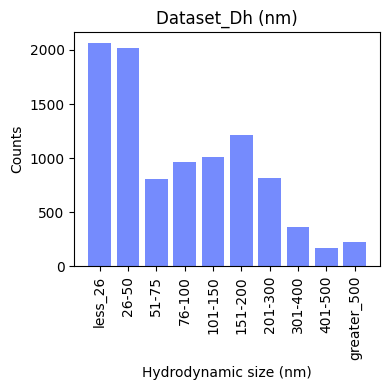

In [17]:
from pandas.api.types import CategoricalDtype

# Define the desired order for the x-axis
desired_order = ["less_26", "26-50", "51-75", "76-100", "101-150", "151-200", 
            "201-300", "301-400", "401-500", "greater_500"]
# Ensure the column 'Size_DLS_nm' is in the desired categorical order
Size = Finalized1['Dh_group'].astype(CategoricalDtype(categories=desired_order, ordered=True))

# Count the occurrences for each category
Size_counts = Size.value_counts().sort_index()

# Plot the bar chart
plt.figure(figsize=(4, 4))
plt.bar(Size_counts.index, Size_counts.values, color='#758bfd')
plt.xticks(rotation = 90)
plt.xlabel('Hydrodynamic size (nm)')
plt.ylabel('Counts')
plt.title(f'Dataset_Dh (nm)')
plt.tight_layout()
plt.show()

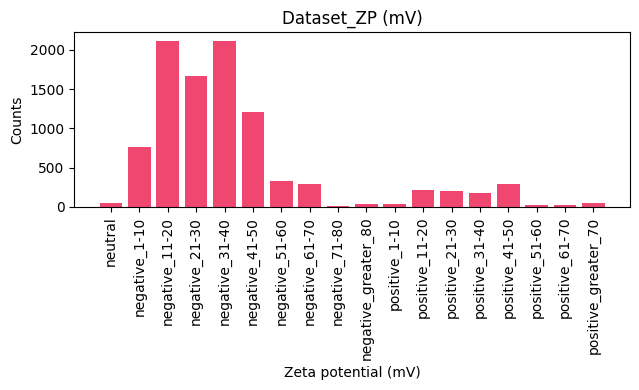

In [18]:
# Define the desired order for the x-axis
desired_order = ["neutral", "negative_1-10", "negative_11-20", "negative_21-30", "negative_31-40",
    "negative_41-50", "negative_51-60", "negative_61-70", "negative_71-80", "negative_greater_80",
    "positive_1-10", "positive_11-20", "positive_21-30", "positive_31-40",
    "positive_41-50", "positive_51-60", "positive_61-70", "positive_greater_70"]

# Ensure the column 'Zeta_potential_mV' is in the desired categorical order
Zeta = Finalized1['ZP_group'].astype(CategoricalDtype(categories=desired_order, ordered=True))

# Count the occurrences for each category
Zeta_counts = Zeta.value_counts().sort_index()

# Plot the bar chart
plt.figure(figsize=(6.5, 4))
plt.bar(Zeta_counts.index, Zeta_counts.values, color='#ef476f')
plt.xticks(rotation = 90)
plt.xlabel('Zeta potential (mV)')
plt.ylabel('Counts')
plt.title(f'Dataset_ZP (mV)')
plt.tight_layout()
plt.show()

# Scenario II: Assign median values for bins in DLS_size and Zeta potential

In [19]:
# Median maps 
size_medians = {
    'less_26':        13,
    '26-50':          38,
    '51-75':          63,
    '76-100':         88,
    '101-150':       125.5,
    '151-200':       175.5,
    '201-300':       250.5,
    '301-400':       350.5,
    '401-500':       450.5,
    'greater_500':   750,
    'greater_1000': 1250
}

zeta_medians = {
    'negative_1-10':    -5,
    'negative_11-20':  -15,
    'negative_21-30':  -25,
    'negative_31-40':  -35,
    'negative_41-50':  -45,
    'negative_51-60':  -55,
    'negative_61-70':  -65,
    'negative_71-80':  -75,
    'negative_81-90':  -85,
    'negative_greater_90': -95,    
    'positive_1-10':     5,
    'positive_11-20':   15,
    'positive_21-30':   25,
    'positive_31-40':   35,
    'positive_41-50':   45,
    'positive_51-60':   55,
    'positive_61-70':   65,
    'positive_71-80':   75,
    'positive_81-90':   85
}

In [20]:
Finalized2 =Final.copy()

# parse any numeric entries 
# (turns e.g. "38" → 38.0, and any labels → NaN)
size_raw = pd.to_numeric(Finalized2['Hydrodynamic_size'], errors='coerce')
zeta_raw = pd.to_numeric(Finalized2['Zeta_potential'],  errors='coerce')

# Build the final “median‐value” columns ─────────────────────────────────
Finalized2['Dh_median'] = np.where(
    Finalized2['Hydrodynamic_size'].isin(size_medians),
    Finalized2['Hydrodynamic_size'].map(size_medians),
    size_raw
)

Finalized2['ZP_median'] = np.where(
    Finalized2['Zeta_potential'].isin(zeta_medians),
    Finalized2['Zeta_potential'].map(zeta_medians),
    zeta_raw
)

# Mean values and standard deviation of label & numerical features

In [21]:
label = ['Cell_viability']

# compute mean and std
stats = Finalized2[label].agg(['mean', 'std']).T

# rename the index to nicer labels
stats.index = ['Cell viability (%)']
print(stats)

                         mean        std
Cell viability (%)  72.356995  33.506825


In [22]:
# list of the numeric columns 
features = ['Diameter', 'Mol_weight', 'Electronegativity', 'Dh_median', 'ZP_median']

# compute mean and std
stats1 = Finalized2[features].agg(['mean', 'std']).T

# rename the index to nicer labels
stats1.index = ['Diameter (nm)', 'Molecular weight (g/mol)', 'Electronegativity', 'Hydrodynamic size (nm)', 'Zeta potential (mV)']
print(stats1)

                                mean         std
Diameter (nm)              51.707475   90.663904
Molecular weight (g/mol)  105.429166  108.410361
Electronegativity           2.558387    0.437294
Hydrodynamic size (nm)    127.921213  221.596658
Zeta potential (mV)       -22.651813   24.769129


In [23]:
# list of the numeric columns 
features2 = ['Time', 'Concentration']

modes = Finalized2[features2].mode().iloc[0]
mins  = Finalized2[features2].min()
maxs  = Finalized2[features2].max()
stats2 = pd.DataFrame({'mode': modes, 'min': mins, 'max': maxs})
# rename the index to nicer labels
stats2.index = ['Exposure time (h)', 'Concentration (µg/mL)']
print(stats2)

                        mode       min      max
Exposure time (h)       24.0  0.083333    240.0
Concentration (µg/mL)  100.0  0.000218  30000.0


# Feature Consolidation

In [24]:
# Multilabel: a coating appears in every category it genuinely belongs to.
# Combination coatings (X/Y, X-Y) are tagged per component.
coating_mapping = {
    # no coating at all
    'is_Unmodified': [
        'Unmodified',
    ],
    # whole organisms, tissue extracts, complex biological mixtures
    'is_Biological': [
        'digestive_enzymes', 'Bacteria', 'Fungi', 'Plant_extract',
        'Algae_extract', 'Curosurf', 'm_PEG_luteolin', 'Betulin',
        'Betulin_PEG',
    ],
    # PEG and other synthetic/natural polymers (the polymer bucket)
    'is_PEG_Polymer': [
        'PEG', 'PVP', 'PEG-FA', 'PEI', 'PVP_DPPC', 'Betulin_PEG', 
        'PEG_AscorbicAcid', 'bPEI', 'm_PEG_luteolin', 'PVA', 'PAA',
    ],
    # small-molecule ligands and simple functional groups
    'is_FuncGroup': [
        'dansylamide', 'COOH', 'NH2', 'SO3H', 'CHO', 'Citrate', 'Ph',
        'PEG-FA', 'Silica-FA', 'Silica-NH2', 'MSA', 'FA', 'CyA', 'CH3',
        'PEG_AscorbicAcid', 'Citrate-Lactose', 'Citrate-Oligonucleotide', 
        'Citrate/Odorranain_A_OA1', 'AscorbicAcid', 'TPPTS', 
        'Toluidine_blue_O/citrate', 'Tertiary_amine', 
    ],
    # silica and other inorganic coatings (oxides, carbon, clay)
    'is_Silica_Inorganic': [
        'alumina', 'Silica-FA', 'Silica', 'Silica-NH2', 'Carbon',
        'bentonite/starch',
    ],
    # lipids, phospholipids, bile acids, fatty acids
    'is_Lipid_Bile_Acid': [
        'Liposome', 'OleicAcid', 'DPPC', 'UDCA', 'Cholic_Acid',
        'Deoxy_Cholic_Acid', 'PVP_DPPC', 'Curosurf',
        'Alpha_lipolic_acid',
    ],
    # polysaccharides and sugars (purified biopolymers go here, not Biological)
    'is_Carbohydrate': [
        'Chitosan', 'Dextran', 'SodiumAlginate', 'Citrate-Lactose',
        'Glucose', 'Lactose', 'glu/ssDNA', 'lac/ssDNA',
        'Toluidine_blue_O/dextran', 'Fucan', 'bentonite/starch',
        'Cellulose_nanofibril', 'Chitin',
    ],
    # nucleic acids, peptides, proteins, amino acids
    'is_Nucleic_Peptide_AA': [
        'digestive_enzymes', 'L-arginine-R', 'Cysteine', 'GSH',
        'Citrate-Oligonucleotide', 'HSA', 'ssDNA', 'glu/ssDNA',
        'lac/ssDNA', 'NAC', 'Soybean_agglutinin/PEG',
        'Citrate/Odorranain_A_OA1', 'CCK_peptide',
    ],
}


# Pad shorter lists with None (ignored below) so all lists share one length.
_max_len = max(len(v) for v in coating_mapping.values())
coating_mapping = {
    k: v + [None] * (_max_len - len(v)) for k, v in coating_mapping.items()
}

# Apply: one 0/1 column per category (multilabel, so a row can score in
# several columns; 'Unmodified' rows score only in is_Unmodified).
for cat, members in coating_mapping.items():
    member_set = {m for m in members if m is not None}
    Finalized2[cat] = Finalized2['Surf_func'].isin(member_set).astype(int)

# Verify: counts per category
print("Rows per category (1 = tagged):")
print(Finalized2[list(coating_mapping)].sum().sort_values(ascending=False))

# Verify: every Surf_func value in the data should land in >= 1 category.
covered = {m for members in coating_mapping.values()
           for m in members if m is not None}
unmapped = sorted(set(Finalized2['Surf_func'].dropna().unique()) - covered)
print("\nUnmapped Surf_func values:", unmapped)
print("Rows with no category at all:",
      (Finalized2[list(coating_mapping)].sum(axis=1) == 0).sum())

# Verify
lengths = {k: len(v) for k, v in coating_mapping.items()}
assert len(set(lengths.values())) == 1, "Mismatch in list lengths!"
print("All lengths match!")

Rows per category (1 = tagged):
is_Unmodified            6024
is_FuncGroup              965
is_Biological             818
is_PEG_Polymer            773
is_Carbohydrate           552
is_Lipid_Bile_Acid        316
is_Nucleic_Peptide_AA     271
is_Silica_Inorganic       170
dtype: int64

Unmapped Surf_func values: []
Rows with no category at all: 0
All lengths match!


In [25]:
# Get Cell_tissue category proportions across the entire dataset
tissue_pct = Finalized2['Cell_tissue'].value_counts(normalize=True) * 100

# Filter categories below 10%
rare_tissue = tissue_pct[tissue_pct < 20].reset_index()
rare_tissue.columns = ['Cell_tissue', 'Percentage']
rare_tissue['Percentage'] = rare_tissue['Percentage'].round(3)

print(f"Total categories: {len(tissue_pct)}")
print(f"Rare categories (<20%): {len(rare_tissue)}\n")
print(rare_tissue.to_string(index=False))

Total categories: 36
Rare categories (<20%): 36

                 Cell_tissue  Percentage
                        Lung      18.010
                        Skin      11.246
                       Blood       8.787
                       Liver       7.688
                       Colon       7.190
                      Cervix       5.965
                     Ascites       5.519
                  BoneMarrow       5.063
                      Breast       4.285
                       Brain       3.766
                      Embryo       3.444
                      Kidney       3.382
              umbilical_cord       3.341
                 cell_hybrid       2.168
                     gastric       1.452
SubcutaneousConnectiveTissue       1.421
                       Heart       1.369
                AdrenalGland       1.276
                       Ovary       0.622
               microvascular       0.581
                      Cornea       0.560
                      testis       0.508
        

In [26]:
tissue_mapping = {
    'Heart': 'Cardiovascular',
    'microvascular': 'Cardiovascular',
    'Aorta': 'Cardiovascular',
    
    'Muscle': 'Musculoskeletal',
    'Bone': 'Musculoskeletal',
    'Connective Tissue': 'Musculoskeletal',
    'SubcutaneousConnectiveTissue': 'Musculoskeletal',
    'FatPad': 'Musculoskeletal',
    
    'Cervix': 'Reproductive',
    'Ovary': 'Reproductive',
    'testis': 'Reproductive',
    'Uterine': 'Reproductive',
    'Amnion': 'Reproductive',
    'Vaginal': 'Reproductive',
    
    'Colon': 'Abdominal_GI',
    'gastric': 'Abdominal_GI',
    'Peritoneal Cavity': 'Abdominal_GI',
    'Pancreas': 'Abdominal_GI',
    'Spleen': 'Abdominal_GI',
    
    'Cornea': 'Sensory_Barrier',
    'Eyes': 'Sensory_Barrier',
    'Buccal mucosa': 'Sensory_Barrier',
    'Teeth': 'Sensory_Barrier',
    'Gingiva': 'Sensory_Barrier',
    
    'Bladder': 'Urinary',
}

# Apply mapping, leaving unmapped categories unchanged
Finalized2['Cell_tissue_GR'] = Finalized2['Cell_tissue'].replace(tissue_mapping)

# Verify
print("Unique categories after grouping:")
print(Finalized2['Cell_tissue_GR'].value_counts())

# Sanity check - confirm unchanged categories are intact
unchanged = ['Lung','Skin','Blood','BoneMarrow','Ascites','Liver',
             'Kidney','Brain','Breast','umbilical_cord','Embryo',
             'cell_hybrid','AdrenalGland']
for cat in unchanged:
    assert cat in Finalized2['Cell_tissue_GR'].values, f"{cat} is missing!"
print("\nAll unchanged categories confirmed intact.")

Unique categories after grouping:
Cell_tissue_GR
Lung               1736
Skin               1084
Abdominal_GI        847
Blood               847
Liver               741
Reproductive        713
Ascites             532
BoneMarrow          488
Breast              413
Brain               363
Embryo              332
Kidney              326
umbilical_cord      322
Musculoskeletal     252
cell_hybrid         209
Cardiovascular      188
AdrenalGland        123
Sensory_Barrier     112
Urinary              11
Name: count, dtype: int64

All unchanged categories confirmed intact.


# ML-ready data export

## Remove outliers (NP w/ too large diameter, exposed to too high conc.)

In [27]:
# thresholds — set these deliberately
# (250 nm / 5000 µg/mL match the inclusion criteria in the manuscript)
SIZE_COL = 'Diameter'  # primary size; see note below on Hydrodynamic
DIAM_MAX = 250          # nm
CONC_MAX = 5000         # µg/mL

In [28]:
Finalized2['is_outlier_size_conc'] = (
    (Finalized2[SIZE_COL] > DIAM_MAX) | (Finalized2['Concentration'] > CONC_MAX)
)

# report what would be cut, and why
print('total rows:', len(Finalized2))
print('diameter over limit:', (Finalized2[SIZE_COL] > DIAM_MAX).sum())
print('concentration over limit:', (Finalized2['Concentration'] > CONC_MAX).sum())
print('either criterion (removed):', Finalized2['is_outlier_size_conc'].sum())
print('remaining:', (~Finalized2['is_outlier_size_conc']).sum())

# filtered copy for the analysis; the original Cytotoxicity stays intact
F2f = Finalized2[~Finalized2['is_outlier_size_conc']].copy()

total rows: 9639
diameter over limit: 275
concentration over limit: 26
either criterion (removed): 301
remaining: 9338


In [29]:
F2f.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9338 entries, 0 to 9638
Data columns (total 37 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Source                 9338 non-null   object 
 1   Year                   9338 non-null   int64  
 2   DOI_No.                9338 non-null   int16  
 3   DOI                    9338 non-null   object 
 4   Cell_viability         7074 non-null   float64
 5   Cytotoxicity           9338 non-null   object 
 6   Core                   9338 non-null   object 
 7   Diameter               9338 non-null   float64
 8   Hydrodynamic_size      9338 non-null   object 
 9   Zeta_potential         9338 non-null   object 
 10  Surf_func              9338 non-null   object 
 11  Assay_viability        9338 non-null   object 
 12  Test_indicator         9338 non-null   object 
 13  Time                   9338 non-null   float64
 14  Concentration          9338 non-null   float64
 15  Cell_morp

In [30]:
cols_to_drop = ['Source', 'Year', 'DOI_No.', 'DOI', 'Hydrodynamic_size', 'Zeta_potential', 
               'is_outlier_size_conc']
NanoToxIn = F2f.drop(columns=Finalized2[cols_to_drop])
NanoToxIn.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9338 entries, 0 to 9638
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Cell_viability         7074 non-null   float64
 1   Cytotoxicity           9338 non-null   object 
 2   Core                   9338 non-null   object 
 3   Diameter               9338 non-null   float64
 4   Surf_func              9338 non-null   object 
 5   Assay_viability        9338 non-null   object 
 6   Test_indicator         9338 non-null   object 
 7   Time                   9338 non-null   float64
 8   Concentration          9338 non-null   float64
 9   Cell_morphol           9338 non-null   object 
 10  Cell_type              9338 non-null   object 
 11  Cell_disease           9338 non-null   object 
 12  Cell_source            9338 non-null   object 
 13  Cell_culture           9338 non-null   object 
 14  Cell_tissue            9338 non-null   object 
 15  Tumor_cel

In [31]:
# Non-numeric columns
cols_to_drop = NanoToxIn.columns[np.r_[0, 3, 7, 8, 17:30]]
Categor = NanoToxIn.drop(columns=cols_to_drop)

# Numeric columns
cols_to_drop2 = NanoToxIn.columns[np.r_[1, 2, 4, 5, 6, 9:17, 21:30]]
Numeric = NanoToxIn.drop(columns=cols_to_drop2)

In [32]:
from scipy.stats import chi2_contingency

# Function to calculate Cramér's V
def cramers_v(x, y):
    contingency_table = pd.crosstab(x, y)
    chi2 = chi2_contingency(contingency_table)[0]
    n = contingency_table.sum().sum()
    r, k = contingency_table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# Calculate correlation matrix for a mix of categorical and numerical variables
def mixed_correlation_matrix(df):
    corr_matrix = pd.DataFrame(index=df.columns, columns=df.columns)
    
    for col1 in df.columns:
        for col2 in df.columns:
            if df[col1].dtype == 'object' and df[col2].dtype == 'object':
                # Categorical vs Categorical: Use Cramér's V
                corr_matrix.loc[col1, col2] = cramers_v(df[col1], df[col2])
            elif df[col1].dtype != 'object' and df[col2].dtype != 'object':
                # Numerical vs Numerical: Use Pearson correlation
                corr_matrix.loc[col1, col2] = df[col1].corr(df[col2])
            else:
                # Mixed types (Categorical vs Numerical): Skip or handle as needed
                corr_matrix.loc[col1, col2] = np.nan
    
    return corr_matrix.astype(float)

# Correlation Analysis of the Original Variables

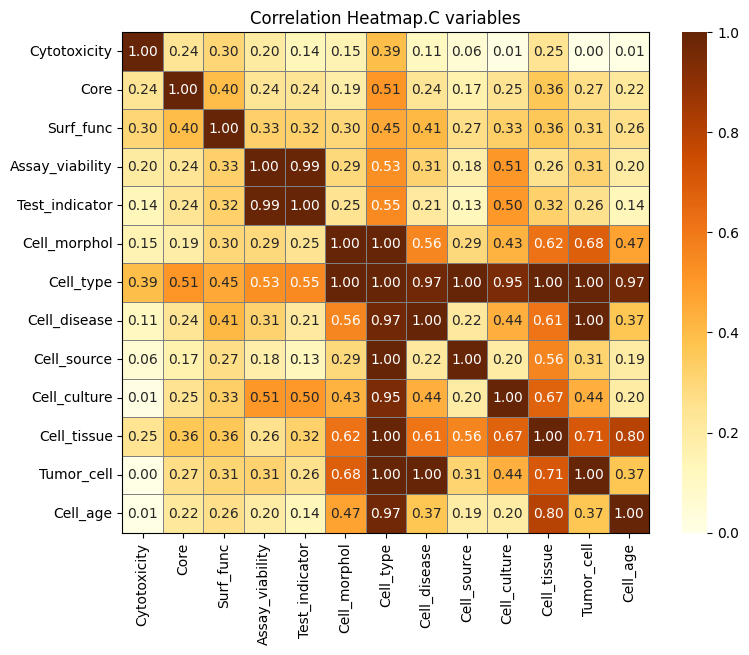

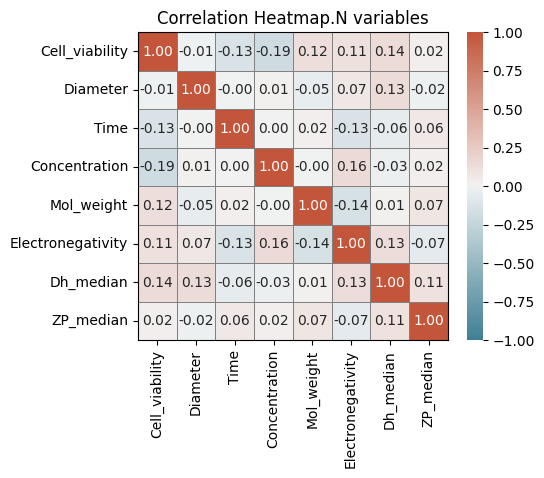

In [33]:
# Calculate the mixed correlation matrix
correlation_matrix = mixed_correlation_matrix(Categor)

# Plot the heatmap with a custom color map
plt.figure(figsize=(8.5, 6.5))

matrix = np.triu(np.ones_like(correlation_matrix, dtype=bool))  # take lower correlation matrix
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="YlOrBr", cbar=True,
    linewidths=0.5,  linecolor="gray", # Adds gridlines
    vmin=0, vmax=1                # Minimum and Maximum value for the color range
    )  

# Draw full borders
plt.gca().spines['top'].set_visible(True)
plt.gca().spines['right'].set_visible(True)
plt.gca().spines['bottom'].set_visible(True)
plt.gca().spines['left'].set_visible(True)

plt.title("Correlation Heatmap.C variables")
plt.show()



# Calculate the mixed correlation matrix
Ncorrelation_matrix = mixed_correlation_matrix(Numeric)

# Plot the heatmap with a custom color map
plt.figure(figsize=(5, 4))
custom_cmap = sns.diverging_palette(220, 20, as_cmap=True)
matrix = np.triu(np.ones_like(Ncorrelation_matrix, dtype=bool)) # take lower correlation matrix
sns.heatmap(Ncorrelation_matrix, annot=True, fmt=".2f", cmap=custom_cmap, cbar=True,
    linewidths=0.5,  linecolor="gray", # Adds gridlines
    vmin=-1, vmax=1                # Minimum and Maximum value for the color range
    )  

# Draw full borders
plt.gca().spines['top'].set_visible(True)
plt.gca().spines['right'].set_visible(True)
plt.gca().spines['bottom'].set_visible(True)
plt.gca().spines['left'].set_visible(True)

plt.title("Correlation Heatmap.N variables")
plt.show()

In [34]:
# remove common high-correlated variables (r > 0.8)
# between classification and regression tasks (NOT provided in this notebook)
correlated = ['Test_indicator', 'Cell_tissue', 'Cell_disease']
NanoToxIn1 = NanoToxIn.drop(columns=NanoToxIn[correlated])

In [35]:
# Reorder columns to match the exact order used during model training.
# This notebook was simplified/rebuilt from my original backup file, so the
# column order no longer matches the trained model's feature order.
# SHAP relies on positional indexing, so a mismatched order silently
# mislabels the SHAP values — reordering here prevents that collapse.

col = [1, 2, 4, 5, 8, 9, 12, 10, 11, 13, 3, 6, 7, 14, 15, 16, 17, 0]
NanoToxIn1_reordered = NanoToxIn1.iloc[:, col]

In [36]:
# Export to a CSV file
NanoToxIn1_reordered.to_csv('NanoTox_9338.csv', index=False)

# Two-tier feature reduction method (8 is_ cols and Cell_tissue_GR)

In [37]:
group_cols = [
    'is_Unmodified',
    'is_Biological',
    'is_PEG_Polymer',
    'is_FuncGroup',
    'is_Silica_Inorganic',
    'is_Lipid_Bile_Acid',
    'is_Carbohydrate',
    'is_Nucleic_Peptide_AA'
]

def reconstruct_groups(row):
    active = [col.replace('is_', '') for col in group_cols if row[col] == 1]
    return '|'.join(active)

NanoToxIn['surf_func_grouped'] = NanoToxIn.apply(reconstruct_groups, axis=1)

In [38]:
NanoToxIn.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9338 entries, 0 to 9638
Data columns (total 31 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Cell_viability         7074 non-null   float64
 1   Cytotoxicity           9338 non-null   object 
 2   Core                   9338 non-null   object 
 3   Diameter               9338 non-null   float64
 4   Surf_func              9338 non-null   object 
 5   Assay_viability        9338 non-null   object 
 6   Test_indicator         9338 non-null   object 
 7   Time                   9338 non-null   float64
 8   Concentration          9338 non-null   float64
 9   Cell_morphol           9338 non-null   object 
 10  Cell_type              9338 non-null   object 
 11  Cell_disease           9338 non-null   object 
 12  Cell_source            9338 non-null   object 
 13  Cell_culture           9338 non-null   object 
 14  Cell_tissue            9338 non-null   object 
 15  Tumor_cel

In [39]:
# Non-numeric columns
cols_to_drop = NanoToxIn.columns[np.r_[0, 3, 4, 7, 8, 10, 14, 17:29]]
Categor2 = NanoToxIn.drop(columns=cols_to_drop)

# Numeric columns
cols_to_drop2 = NanoToxIn.columns[np.r_[1, 2, 4, 5, 6, 9:17, 21:31]]
Numeric2 = NanoToxIn.drop(columns=cols_to_drop2)

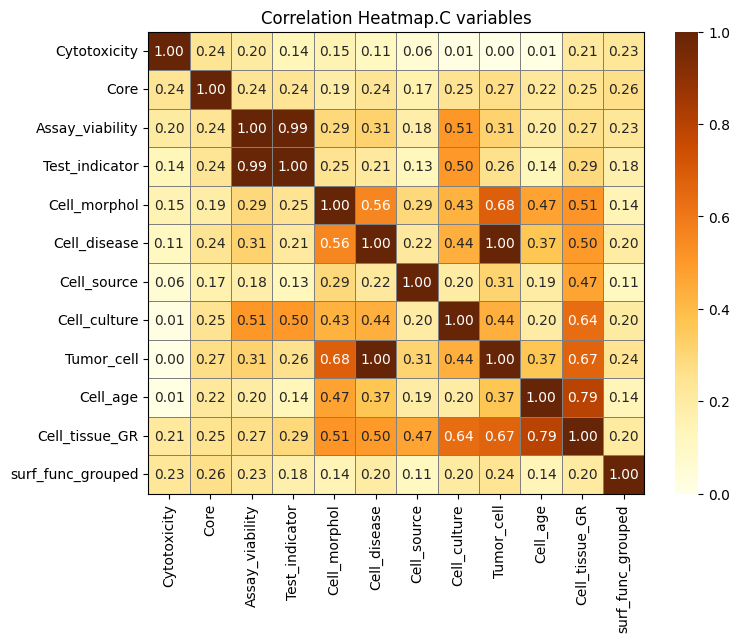

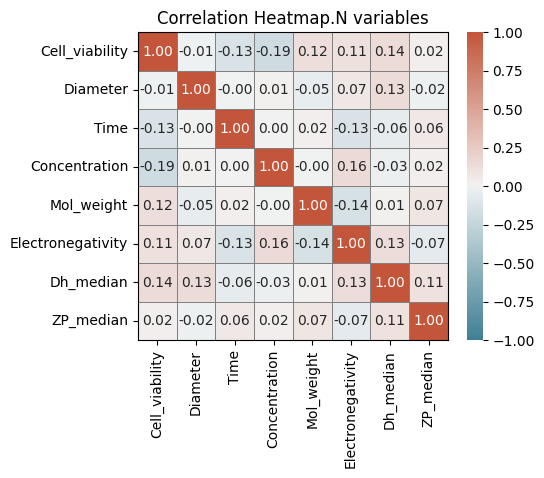

In [40]:
# Calculate the mixed correlation matrix
correlation_matrix = mixed_correlation_matrix(Categor2)

# Plot the heatmap with a custom color map
plt.figure(figsize=(8, 6))

matrix = np.triu(np.ones_like(correlation_matrix, dtype=bool))  # take lower correlation matrix
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="YlOrBr", cbar=True,
    linewidths=0.5,  linecolor="gray", # Adds gridlines
    vmin=0, vmax=1                # Minimum and Maximum value for the color range
    )  

# Draw full borders
plt.gca().spines['top'].set_visible(True)
plt.gca().spines['right'].set_visible(True)
plt.gca().spines['bottom'].set_visible(True)
plt.gca().spines['left'].set_visible(True)

plt.title("Correlation Heatmap.C variables")
plt.show()



# Calculate the mixed correlation matrix
Ncorrelation_matrix = mixed_correlation_matrix(Numeric2)

# Plot the heatmap with a custom color map
plt.figure(figsize=(5, 4))
custom_cmap = sns.diverging_palette(220, 20, as_cmap=True)
matrix = np.triu(np.ones_like(Ncorrelation_matrix, dtype=bool)) # take lower correlation matrix
sns.heatmap(Ncorrelation_matrix, annot=True, fmt=".2f", cmap=custom_cmap, cbar=True,
    linewidths=0.5,  linecolor="gray", # Adds gridlines
    vmin=-1, vmax=1                # Minimum and Maximum value for the color range
    )  

# Draw full borders
plt.gca().spines['top'].set_visible(True)
plt.gca().spines['right'].set_visible(True)
plt.gca().spines['bottom'].set_visible(True)
plt.gca().spines['left'].set_visible(True)

plt.title("Correlation Heatmap.N variables")
plt.show()

In [41]:
# remove common high-correlated variables (r > 0.7)
# between classification and regression tasks (NOT provided in this notebook)
correlated = ['Assay_viability', 'Cell_age', 'Tumor_cell']
NanoToxIn2 = NanoToxIn.drop(columns=NanoToxIn[correlated])

In [42]:
NanoToxIn2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9338 entries, 0 to 9638
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Cell_viability         7074 non-null   float64
 1   Cytotoxicity           9338 non-null   object 
 2   Core                   9338 non-null   object 
 3   Diameter               9338 non-null   float64
 4   Surf_func              9338 non-null   object 
 5   Test_indicator         9338 non-null   object 
 6   Time                   9338 non-null   float64
 7   Concentration          9338 non-null   float64
 8   Cell_morphol           9338 non-null   object 
 9   Cell_type              9338 non-null   object 
 10  Cell_disease           9338 non-null   object 
 11  Cell_source            9338 non-null   object 
 12  Cell_culture           9338 non-null   object 
 13  Cell_tissue            9338 non-null   object 
 14  Mol_weight             9338 non-null   float64
 15  Electrone

In [43]:
# Reorder columns to match the exact order used during model training.
# This notebook was simplified/rebuilt from my original backup file, so the
# column order no longer matches the trained model's feature order.
# SHAP relies on positional indexing, so a mismatched order silently
# mislabels the SHAP values — reordering here prevents that collapse.

col = [1, 2, 5, 8, 10, 11, 12, 26, 3, 6, 7, 14, 15, 18, 19, 20, 21, 22, 23, 24, 25, 16, 17, 0, 27]
NanoToxIn2_reordered = NanoToxIn2.iloc[:, col]

In [44]:
# Export to a CSV file
NanoToxIn2_reordered.to_csv('NanoTox_9338_2.csv', index=False)

# External dataset

In [45]:
Finalex = pd.read_csv('ExRaw.csv')  # Sample size at this stage: 1327
Finalex.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1327 entries, 0 to 1326
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Source             1327 non-null   object 
 1   Year               1327 non-null   int64  
 2   DOI                1327 non-null   object 
 3   Cell_viability     1327 non-null   float64
 4   Cytotoxicity       1327 non-null   object 
 5   Core               1327 non-null   object 
 6   Diameter           1327 non-null   float64
 7   Hydrodynamic_size  1327 non-null   float64
 8   Zeta_potential     1327 non-null   float64
 9   Surf_func          1327 non-null   object 
 10  Assay_viability    1327 non-null   object 
 11  Test_indicator     1327 non-null   object 
 12  Time               1327 non-null   int64  
 13  Concentration      1327 non-null   float64
 14  Cell_tissue        1327 non-null   object 
 15  Cell_age           1327 non-null   object 
 16  Cell_type          1327 

# Add 2 new NP properties: electronegativity and molecular weight of core material

In [46]:
# Extract unique core formulas
unique_cores = Finalex['Core'].dropna().unique()

# Compute properties once per unique formula
props = {core: get_material_properties_optimized(core) for core in unique_cores}

In [47]:
# Build mapping dicts for weight and electronegativity
mw_map = {core: val[0] for core, val in props.items()}
en_map = {core: val[1] for core, val in props.items()}

# Map the results back into the original DataFrame
Finalex['Mol_weight'] = Finalex['Core'].map(mw_map)
Finalex['Electronegativity'] = Finalex['Core'].map(en_map)

In [48]:
# --- Parenthesized formulas: same function as every other row ---
for core in ['Ca10(PO4)6(OH)2', 'Fe4(Fe(CN)6)3']:
    mw, chi = get_material_properties_optimized(expand_parentheses(core))
    m = Finalex['Core'] == core
    Finalex.loc[m & Finalex['Mol_weight'].isna(), 'Mol_weight'] = mw
    Finalex.loc[m & Finalex['Electronegativity'].isna(), 'Electronegativity'] = chi
    print(f"{core}: MW = {mw:.2f}, EN = {chi:.3f}")
# expect: Ca10(PO4)6(OH)2: MW = 1004.61, EN = 2.659
#         Fe4(Fe(CN)6)3:      MW = 859.24,  EN = 2.638

# --- Ag/Au alloy: mean of constituents from mendeleev's own values ---
# (assumes ~50:50; reweight if the paper reports a different ratio)
ag, au = element('Ag'), element('Au')
alloy_mw = (ag.atomic_weight + au.atomic_weight) / 2
alloy_en = (ag.electronegativity('pauling') + au.electronegativity('pauling')) / 2
print(f"Ag/Au: MW = {alloy_mw:.2f}, EN = {alloy_en:.3f}")  # expect 152.42, 2.165
m = Finalex['Core'] == 'Ag/Au'
Finalex.loc[m & Finalex['Mol_weight'].isna(), 'Mol_weight'] = alloy_mw
Finalex.loc[m & Finalex['Electronegativity'].isna(), 'Electronegativity'] = alloy_en

# --- Guardrail: surface any core still missing descriptors ---
for col in ['Mol_weight', 'Electronegativity']:
    missing = Finalex.loc[Finalex[col].isna(), 'Core'].unique()
    if len(missing):
        print(f"WARNING: {col} still NaN for cores: {list(missing)}")

Ca10(PO4)6(OH)2: MW = 1004.61, EN = 2.659
Fe4(Fe(CN)6)3: MW = 859.24, EN = 2.638
Ag/Au: MW = 152.42, EN = 2.165


In [49]:
with_year = Finalex.dropna(subset=['Year'])

# Count DOIs per year (unique count)
doi_counts = with_year.groupby(with_year['Year'].astype(int))['DOI'].nunique()
doi_counts

Year
2012    1
2013    4
2014    3
2015    4
2016    6
2017    9
2018    8
2019    4
2020    9
2021    3
2022    3
2023    4
2024    2
2025    1
Name: DOI, dtype: int64

In [50]:
cols_idx = [5, 9, 10, 11] + list(range(14, 21))

for col in Finalex.columns[cols_idx]:
    unique_vals = Finalex[col].unique()
    num_unique_vals = len(unique_vals)

    print(f"\nColumn: {col}")
    print(f"Number of unique values: {num_unique_vals}")
    print(f"Unique values: {unique_vals[:11]} ...")


Column: Core
Number of unique values: 15
Unique values: ['TiO2' 'CuO' 'Ag' 'SiO2' 'ZnO' 'Pt' 'Fe3O4' 'NiO' 'Au' 'Fe4(Fe(CN)6)3'
 'MnO2'] ...

Column: Surf_func
Number of unique values: 29
Unique values: ['Unmodified' 'PEG' 'Plant_extract' 'PVP' 'PAA' 'PVA' 'Citrate' 'FA'
 'Carbon' 'HSA' 'Cysteine'] ...

Column: Assay_viability
Number of unique values: 12
Unique values: ['TrypanBlue' 'MTT' 'CCK-8/WST-8' 'NRU' 'MTS' 'alamarBlue' 'LDH'
 'sulforhodamine_b' 'Annexin_V' 'CellTiterGlo' 'WST_1'] ...

Column: Test_indicator
Number of unique values: 9
Unique values: ['dead_cell' 'tetrazolium' 'NeutralRed' 'Resazurin_reduction'
 'LDH_activity' 'cell_mass' 'live_dead_cell' 'ATP' 'live_cell'] ...

Column: Cell_tissue
Number of unique values: 21
Unique values: ['Colon' 'Aorta' 'Blood' 'Ascites' 'Buccal mucosa' 'Breast' 'Lung' 'Liver'
 'SubcutaneousConnectiveTissue' 'Ovary' 'BoneMarrow'] ...

Column: Cell_age
Number of unique values: 2
Unique values: ['NonEmbryonic' 'Embryonic'] ...

Column: Cell_ty

# Feature consolidation

In [51]:
# Multilabel: a coating appears in every category it genuinely belongs to.
# Combination coatings (X/Y, X-Y) are tagged per component.
coating_mapping = {
    'is_Unmodified': [
        'Unmodified',
    ],
    'is_Biological': [
        'Plant_extract', 'Fungi', 'Collagen hydrolysate', 'KG-1@UA-Hyd',
         'KG-1@C', 'Collagen hydrolysate + PVP', 'DSPE-PEG-HA@RBC-M', 'FBS',
    ],
    'is_PEG_Polymer': [
        'PEG', 'PVP', 'Collagen hydrolysate + PVP', 'DSPE-PEG-HA@RBC-M', 
        'PVA', 'PAA', 'PAH'
    ],
    'is_FuncGroup': [
        'Citrate', 'FA', 'BSA-ICG', 'Cys-FA', 'cysteine@MTX@RGD', 'silane', 
        'UA-Hyd', 'KG-1@UA-Hyd',
    ],
    'is_Silica_Inorganic': [
        'Carbon', 'GO',
    ],
    'is_Lipid_Bile_Acid': [
        'DSPE-PEG-HA@RBC-M', 'KG-1@UA-Hyd', 'KG-1@C', 'UA-Hyd',
    ],
    'is_Carbohydrate': [
        'Dextrin', 'DSPE-PEG-HA@RBC-M', 'HA', 'starch',
    ],
    'is_Nucleic_Peptide_AA': [
        'HSA', 'Cysteine', 'Collagen hydrolysate', 'BSA-ICG', 'Cys-FA',
        'Collagen hydrolysate + PVP', 'cysteine@MTX@RGD', 'L-serine',
    ],
}

# Pad shorter lists with None (ignored below) so all lists share one length.
_max_len = max(len(v) for v in coating_mapping.values())
coating_mapping = {
    k: v + [None] * (_max_len - len(v)) for k, v in coating_mapping.items()
}

# Apply: one 0/1 column per category (multilabel, so a row can score in
# several columns; 'Unmodified' rows score only in is_Unmodified).
for cat, members in coating_mapping.items():
    member_set = {m for m in members if m is not None}
    Finalex[cat] = Finalex['Surf_func'].isin(member_set).astype(int)

# Verify: counts per category
print("Rows per category (1 = tagged):")
print(Finalex[list(coating_mapping)].sum().sort_values(ascending=False))

# Verify: every Surf_func value in the data should land in >= 1 category.
covered = {m for members in coating_mapping.values()
           for m in members if m is not None}
unmapped = sorted(set(Finalex['Surf_func'].dropna().unique()) - covered)
print("\nUnmapped Surf_func values:", unmapped)
print("Rows with no category at all:",
      (Finalex[list(coating_mapping)].sum(axis=1) == 0).sum())

# Verify
lengths = {k: len(v) for k, v in coating_mapping.items()}
assert len(set(lengths.values())) == 1, "Mismatch in list lengths!"
print("All lengths match!")

Rows per category (1 = tagged):
is_Unmodified            740
is_Biological            201
is_FuncGroup             192
is_Lipid_Bile_Acid       123
is_Nucleic_Peptide_AA    119
is_PEG_Polymer           111
is_Silica_Inorganic       95
is_Carbohydrate           53
dtype: int64

Unmapped Surf_func values: []
Rows with no category at all: 0
All lengths match!


In [52]:
tissue_mapping = {
    'Aorta': 'Cardiovascular',

    'Connective Tissue': 'Musculoskeletal',
    'SubcutaneousConnectiveTissue': 'Musculoskeletal',
    
    'Cervix': 'Reproductive',
    'Ovary': 'Reproductive',
    'testis': 'Reproductive',
    
    'Colon': 'Abdominal_GI',
    'Pharynx': 'Abdominal_GI',
    
    'Buccal mucosa': 'Sensory_Barrier',
}

# Apply mapping, leaving unmapped categories unchanged
Finalex['Cell_tissue_GR'] = Finalex['Cell_tissue'].replace(tissue_mapping)

# Verify
print("Unique categories after grouping:")
print(Finalex['Cell_tissue_GR'].value_counts())

# Sanity check - confirm unchanged categories are intact
unchanged = ['Lung','Skin','Blood','BoneMarrow','Ascites','Liver','Kidney',
             'Brain','Breast','umbilical_cord','Embryo','AdrenalGland']
for cat in unchanged:
    assert cat in Finalex['Cell_tissue_GR'].values, f"{cat} is missing!"
print("\nAll unchanged categories confirmed intact.")

Unique categories after grouping:
Cell_tissue_GR
Ascites            166
Lung               154
Skin               139
Kidney             125
Liver              119
Abdominal_GI        80
Blood               73
BoneMarrow          72
Brain               72
umbilical_cord      58
Reproductive        50
AdrenalGland        48
Breast              45
Musculoskeletal     45
Cardiovascular      30
Embryo              27
Sensory_Barrier     24
Name: count, dtype: int64

All unchanged categories confirmed intact.


# Mean values and standard deviation of label & numerical features

In [53]:
label = ['Cell_viability']

# compute mean and std
stats = Finalex[label].agg(['mean', 'std']).T

# rename the index to nicer labels
stats.index = ['Cell viability (%)']
print(stats)

                         mean        std
Cell viability (%)  71.713248  33.420486


In [54]:
# list of the numeric columns 
features = ['Diameter', 'Mol_weight', 'Electronegativity', 'Hydrodynamic_size', 'Zeta_potential']

# compute mean and std
stats1 = Finalex[features].agg(['mean', 'std']).T

# rename the index to nicer labels
stats1.index = ['Diameter (nm)', 'Molecular weight (g/mol)', 'Electronegativity', 'Hydrodynamic size (nm)', 'Zeta potential (mV)']
print(stats1)

                                mean         std
Diameter (nm)              60.631334   49.938045
Molecular weight (g/mol)  121.830504  135.408904
Electronegativity           2.535547    0.271012
Hydrodynamic size (nm)    193.511824  172.972349
Zeta potential (mV)       -12.420422   22.476161


In [55]:
# list of the numeric columns 
features2 = ['Time', 'Concentration']

modes = Finalex[features2].mode().iloc[0]
mins  = Finalex[features2].min()
maxs  = Finalex[features2].max()
stats2 = pd.DataFrame({'mode': modes, 'min': mins, 'max': maxs})
# rename the index to nicer labels
stats2.index = ['Exposure time (h)', 'Concentration (µg/mL)']
print(stats2)

                       mode           min     max
Exposure time (h)      24.0  1.000000e+00    96.0
Concentration (µg/mL)  10.0  1.000000e-09  1000.0


In [56]:
External = Finalex.drop(columns=Finalex.columns[[0, 1, 2]])

In [57]:
External = External.rename(columns={'Hydrodynamic_size': 'Dh_median', 'Zeta_potential': 'ZP_median'})
External.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1327 entries, 0 to 1326
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Cell_viability         1327 non-null   float64
 1   Cytotoxicity           1327 non-null   object 
 2   Core                   1327 non-null   object 
 3   Diameter               1327 non-null   float64
 4   Dh_median              1327 non-null   float64
 5   ZP_median              1327 non-null   float64
 6   Surf_func              1327 non-null   object 
 7   Assay_viability        1327 non-null   object 
 8   Test_indicator         1327 non-null   object 
 9   Time                   1327 non-null   int64  
 10  Concentration          1327 non-null   float64
 11  Cell_tissue            1327 non-null   object 
 12  Cell_age               1327 non-null   object 
 13  Cell_type              1327 non-null   object 
 14  Tumor_cell             1327 non-null   object 
 15  Cell

In [58]:
# Export to a CSV file
External.to_csv('External1327.csv', index=False)

In [59]:
pip install plotly


[notice] A new release of pip is available: 23.0.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [60]:
# create coating column by getting the names of "is_" variables that are True
coating_vars = [c for c in External.columns if c.startswith("is_")]

# Get the coating name(s) for each row
External["Coating"] = External[coating_vars].apply(
    lambda row: ', '.join([col.replace('is_', '') for col in coating_vars if row[col] == 1]),
    axis=1
)

In [61]:
import plotly.graph_objects as go

# 1. Prepare the DataFrame
Category = External[['Core', 'Coating', 'Test_indicator', 'Cell_source', 'Cell_tissue_GR',
                  'Cell_culture', 'Cell_morphol', 'Cytotoxicity']].copy()
dims = ['Core', 'Coating', 'Test_indicator', 'Cell_source', 'Cell_tissue_GR',
        'Cell_culture', 'Cell_morphol', 'Cytotoxicity']

# 2. Collapse rare categories
thresh = 0.03   # 3%
for col in dims:
    freqs = Category[col].value_counts(normalize=True)
    rare  = freqs[freqs < thresh].index.tolist()
    Category[col] = Category[col].astype(object)
    Category.loc[Category[col].isin(rare), col] = 'Other'

# 3. Build node labels WITH custom x-positions
nodes = []
node_display = []
node_x = []  # Add x-coordinates
node_y = []  # Initialize y-coordinates

last_dim = dims[-1]

# Define custom x-positions for each column (0 to 1 scale)
# Adjust these to give more space where needed
col_positions = {
    'Core': 0.0,
    'Coating': 0.09,
    'Test_indicator': 0.31,
    'Cell_source': 0.5,
    'Cell_tissue_GR': 0.59,
    'Cell_culture': 0.76,
    'Cell_morphol': 0.86,
    'Cytotoxicity': 1.0
}

for col in dims:
    uniqs = Category[col].astype(str).unique()
    x_pos = col_positions[col]

    for idx, val in enumerate(sorted(uniqs, key=lambda x: str(x))):
        nodes.append(f"{col}: {val}")
        node_x.append(x_pos)
        node_y.append(0.001)  # Small value to enable custom x positioning

        if col == last_dim:
            node_display.append("")
        else:
            try:
                num_val = float(val)
                if num_val.is_integer():
                    node_display.append(str(int(num_val)))
                else:
                    node_display.append(str(num_val))
            except ValueError:
                node_display.append(val)

node_index = {k: i for i, k in enumerate(nodes)}

# 4. Helper for links
def make_links(src, tgt):
    grp = Category.groupby([src, tgt]).size().reset_index(name='count')
    links = []
    for _, row in grp.iterrows():
        s_lbl = node_index[f"{src}: {row[src]}"]
        t_lbl = node_index[f"{tgt}: {row[tgt]}"]
        links.append(dict(source=s_lbl, target=t_lbl, value=row['count']))
    return links

# 5. Build all forward links
links = []
for i in range(len(dims)-1):
    links += make_links(dims[i], dims[i+1])

# 6. Draw Sankey with custom positioning
fig = go.Figure(go.Sankey(
    arrangement='snap',  # Force Plotly to respect custom positions
    node = dict(
        label=node_display,
        x=node_x,  # Custom x positions
        y=node_y,  # Required for custom positioning to work
        pad=15, thickness=20
    ),
    link = dict(
        source=[l['source'] for l in links],
        target=[l['target'] for l in links],
        value =[l['value']  for l in links]
    )
))

fig.update_layout(
    margin=dict(t=350, l=20, r=20, b=20),
    font_size=18, width=1200, height=800
)

# 7. Add column-name headings with custom positions
for col in dims:
    x = col_positions[col]
    fig.add_annotation(
        x=x, y=1.05,
        xref="paper", yref="paper",
        text=f"<b>{col}</b>",
        showarrow=False, textangle=270,
        xanchor="center", yanchor="bottom",
        font=dict(size=20)
    )
    
fig.write_html("figure.html")